## Load libraries

In [219]:
import polars as pl
import os
from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import StandardScaler
import polars as pl
pl.Config.set_tbl_rows(20)  # show up to 20 rows
import polars.selectors as cs
import seaborn as sns
sns.set_style("darkgrid")  # darkgrid
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd

In [220]:
def csv_to_parquet(path):
    os.makedirs("raw_data", exist_ok=True)
    filename = os.path.basename(path)
    parquet_filename = filename.replace(".csv", ".parquet")
    parquet_path = os.path.join(".\\raw_data", parquet_filename)
    # lazy scan (does NOT load everything into RAM)
    lf = pl.scan_csv(
        path,
        infer_schema_length=1000,
        ignore_errors=True
    )
    print(parquet_path)
    # stream directly to parquet
    lf.sink_parquet(
        parquet_path,
        compression="snappy"
    )
    print(f"Saved Parquet file to: {parquet_path}")

### Convert pandas to polar

In [221]:
has_parquet = any(f.endswith(".parquet") for f in os.listdir("raw_data"))

if has_parquet:
    print("Parquet file already exists in data folder")
else:
    print("No parquet file found. Converting CSV → Parquet...")
    csv_to_parquet("./raw_data/accepted_2007_to_2018Q4.csv")

Parquet file already exists in data folder


### Read accepted_df

In [222]:
# Never use CSV again
accepted_df = pl.read_parquet("./raw_data/accepted_2007_to_2018Q4.parquet")
accepted_df.head()

id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,fico_range_low,fico_range_high,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,…,total_il_high_credit_limit,revol_bal_joint,sec_app_fico_range_low,sec_app_fico_range_high,sec_app_earliest_cr_line,sec_app_inq_last_6mths,sec_app_mort_acc,sec_app_open_acc,sec_app_revol_util,sec_app_open_act_il,sec_app_num_rev_accts,sec_app_chargeoff_within_12_mths,sec_app_collections_12_mths_ex_med,sec_app_mths_since_last_major_derog,hardship_flag,hardship_type,hardship_reason,hardship_status,deferral_term,hardship_amount,hardship_start_date,hardship_end_date,payment_plan_start_date,hardship_length,hardship_dpd,hardship_loan_status,orig_projected_additional_accrued_interest,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
i64,str,f64,f64,f64,str,f64,f64,str,str,str,str,str,f64,str,str,str,str,str,str,str,str,str,str,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,str,str,str,f64,f64,str,f64,f64,f64,str,str,str,str,str,f64,f64,f64
68407277,null,3600.0,3600.0,3600.0,""" 36 months""",13.99,123.03,"""C""","""C4""","""leadman""","""10+ years""","""MORTGAGE""",55000.0,"""Not Verified""","""Dec-2015""","""Fully Paid""","""n""","""https://lendingclub.com/browse/loanDetail.action?loan_id=68407277""",null,"""debt_consolidation""","""Debt consolidation""","""190xx""","""PA""",5.91,0.0,"""Aug-2003""",675.0,679.0,1.0,30.0,null,7.0,0.0,2765.0,29.7,13.0,…,13734.0,null,null,null,null,null,null,null,null,null,null,null,null,null,"""N""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""Cash""","""N""",null,null,null,null,null,null
68355089,null,24700.0,24700.0,24700.0,""" 36 months""",11.99,820.28,"""C""","""C1""","""Engineer""","""10+ years""","""MORTGAGE""",65000.0,"""Not Verified""","""Dec-2015""","""Fully Paid""","""n""","""https://lendingclub.com/browse/loanDetail.action?loan_id=68355089""",null,"""small_business""","""Business""","""577xx""","""SD""",16.06,1.0,"""Dec-1999""",715.0,719.0,4.0,6.0,null,22.0,0.0,21470.0,19.2,38.0,…,24667.0,null,null,null,null,null,null,null,null,null,null,null,null,null,"""N""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""Cash""","""N""",null,null,null,null,null,null
68341763,null,20000.0,20000.0,20000.0,""" 60 months""",10.78,432.66,"""B""","""B4""","""truck driver""","""10+ years""","""MORTGAGE""",63000.0,"""Not Verified""","""Dec-2015""","""Fully Paid""","""n""","""https://lendingclub.com/browse/loanDetail.action?loan_id=68341763""",null,"""home_improvement""",null,"""605xx""","""IL""",10.78,0.0,"""Aug-2000""",695.0,699.0,0.0,null,null,6.0,0.0,7869.0,56.2,18.0,…,14877.0,null,null,null,null,null,null,null,null,null,null,null,null,null,"""N""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""Cash""","""N""",null,null,null,null,null,null
66310712,null,35000.0,35000.0,35000.0,""" 60 months""",14.85,829.9,"""C""","""C5""","""Information Systems Officer""","""10+ years""","""MORTGAGE""",110000.0,"""Source Verified""","""Dec-2015""","""Current""","""n""","""https://lendingclub.com/browse/loanDetail.action?loan_id=66310712""",null,"""debt_consolidation""","""Debt consolidation""","""076xx""","""NJ""",17.06,0.0,"""Sep-2008""",785.0,789.0,0.0,null,null,13.0,0.0,7802.0,11.6,17.0,…,18000.0,null,null,null,null,null,null,null,null,null,null,null,null,null,"""N""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""Cash""","""N""",null,null,null,null,null,null
68476807,null,

In [223]:
print(accepted_df.columns)
print(accepted_df.select('issue_d'))

['id', 'member_id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 'loan_status', 'pymnt_plan', 'url', 'desc', 'purpose', 'title', 'zip_code', 'addr_state', 'dti', 'delinq_2yrs', 'earliest_cr_line', 'fico_range_low', 'fico_range_high', 'inq_last_6mths', 'mths_since_last_delinq', 'mths_since_last_record', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'initial_list_status', 'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt', 'next_pymnt_d', 'last_credit_pull_d', 'last_fico_range_high', 'last_fico_range_low', 'collections_12_mths_ex_med', 'mths_since_last_major_derog', 'policy_code', 'application_type', 'annual_inc_joint', 'dti_joint', 'verification_status_joint', 'acc_now_delinq',

In [224]:
import polars as pl

# schema info
schema = accepted_df.schema

# null counts (computed once)
null_counts = accepted_df.null_count().row(0)

# total rows
n_rows = accepted_df.height

# build summary dataframe efficiently
type_summary = pl.DataFrame({
    "column": accepted_df.columns,
    "dtype": [str(schema[c]) for c in accepted_df.columns],
    "nulls": list(null_counts),
})

# compute percentages
type_summary = (
    type_summary
    .with_columns(
        (
            pl.col("nulls") / n_rows * 100
        ).round(2).alias("null_pct")
    )
    .sort("dtype")
)

print(f"Dataset shape: {accepted_df.shape}")

print("\n----- Null Values Distribution -----")

# avoid printing gigantic dataframe
print(type_summary)

Dataset shape: (2260701, 151)

----- Null Values Distribution -----
shape: (151, 4)
┌───────────────────────────┬─────────┬─────────┬──────────┐
│ column                    ┆ dtype   ┆ nulls   ┆ null_pct │
│ ---                       ┆ ---     ┆ ---     ┆ ---      │
│ str                       ┆ str     ┆ i64     ┆ f64      │
╞═══════════════════════════╪═════════╪═════════╪══════════╡
│ loan_amnt                 ┆ Float64 ┆ 33      ┆ 0.0      │
│ funded_amnt               ┆ Float64 ┆ 33      ┆ 0.0      │
│ funded_amnt_inv           ┆ Float64 ┆ 33      ┆ 0.0      │
│ int_rate                  ┆ Float64 ┆ 33      ┆ 0.0      │
│ installment               ┆ Float64 ┆ 33      ┆ 0.0      │
│ annual_inc                ┆ Float64 ┆ 37      ┆ 0.0      │
│ dti                       ┆ Float64 ┆ 1744    ┆ 0.08     │
│ delinq_2yrs               ┆ Float64 ┆ 62      ┆ 0.0      │
│ fico_range_low            ┆ Float64 ┆ 33      ┆ 0.0      │
│ fico_range_high           ┆ Float64 ┆ 33      ┆ 0.0      │
│

## Data understanding

In [225]:
# count nulls only
n_null_issue = (
    accepted_df
    .select(pl.col("issue_d").is_null().sum())
    .item()
)

print(f"Rows with null issue_d: {n_null_issue}")

# drop nulls directly
accepted_df = accepted_df.drop_nulls(subset=["issue_d"])

print("Remove null in column issue_d done!")
print(f"New shape: {accepted_df.shape}")

Rows with null issue_d: 33
Remove null in column issue_d done!
New shape: (2260668, 151)


In [226]:
# Polar String display
pl.Config.set_fmt_str_lengths(1000)

# Loan Status Distribution
print(f'Total Rows    : {accepted_df.shape[0]:,}')
print(f'Total Columns : {accepted_df.shape[1]}')
date_range = accepted_df.select(
    pl.col("issue_d")
      .str.strptime(pl.Date, "%b-%Y", strict=False)
      .min()
      .alias("min_date"),
    pl.col("issue_d")
      .str.strptime(pl.Date, "%b-%Y", strict=False)
      .max()
      .alias("max_date"),
)

print(
    f"Date Range    : "
    f"{date_range[0, 'min_date']:%b-%Y} → "
    f"{date_range[0, 'max_date']:%b-%Y}"
)

print('\n----- Loan Status Distribution -----')
print(accepted_df['loan_status'].value_counts().sort("count", descending=True))

Total Rows    : 2,260,668
Total Columns : 151
Date Range    : Jun-2007 → Dec-2018

----- Loan Status Distribution -----
shape: (9, 2)
┌─────────────────────────────────────────────────────┬─────────┐
│ loan_status                                         ┆ count   │
│ ---                                                 ┆ ---     │
│ str                                                 ┆ u32     │
╞═════════════════════════════════════════════════════╪═════════╡
│ Fully Paid                                          ┆ 1076751 │
│ Current                                             ┆ 878317  │
│ Charged Off                                         ┆ 268559  │
│ Late (31-120 days)                                  ┆ 21467   │
│ In Grace Period                                     ┆ 8436    │
│ Late (16-30 days)                                   ┆ 4349    │
│ Does not meet the credit policy. Status:Fully Paid  ┆ 1988    │
│ Does not meet the credit policy. Status:Charged Off ┆ 761     │
│ Defaul

## Data cleaning

In [227]:
accepted_df["installment"].value_counts()

installment,count
f64,u32
297.68,3
818.77,4
890.39,2
899.23,1
1197.39,1
919.65,1
883.84,1
1370.94,2
568.22,7


In [228]:
# Keep only known outcomes
accepted_df = accepted_df.filter(
    pl.col("loan_status").is_in(["Fully Paid", "Charged Off"])
)

# Create binary target
accepted_df = accepted_df.with_columns(
    pl.when(pl.col("loan_status") == "Charged Off")
    .then(1)
    .otherwise(0)
    .cast(pl.Int8)
    .alias("target")
)

# Compute default rate
default_rate = (
    accepted_df
    .select(pl.col("target").mean())
    .item()
    * 100
)

print(f"Dataset columns: {accepted_df.columns}")
print(f"Overall Default Rate: {default_rate:.2f}%")

Dataset columns: ['id', 'member_id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 'loan_status', 'pymnt_plan', 'url', 'desc', 'purpose', 'title', 'zip_code', 'addr_state', 'dti', 'delinq_2yrs', 'earliest_cr_line', 'fico_range_low', 'fico_range_high', 'inq_last_6mths', 'mths_since_last_delinq', 'mths_since_last_record', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'initial_list_status', 'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt', 'next_pymnt_d', 'last_credit_pull_d', 'last_fico_range_high', 'last_fico_range_low', 'collections_12_mths_ex_med', 'mths_since_last_major_derog', 'policy_code', 'application_type', 'annual_inc_joint', 'dti_joint', 'verification_status_joint', 

## Feature Selection

In [229]:
# Polars missing value analysis
missing_df = (
    pl.DataFrame({
        "column": accepted_df.columns,
        "null_count": [accepted_df[col].is_null().sum() for col in accepted_df.columns]
    })
    .with_columns(
        (pl.col("null_count") / len(accepted_df) * 100).alias("null_pct")
    )
    .filter(pl.col("null_pct") > 0)
    .sort("null_pct", descending=True)
)

# Summary statistics
over_50 = missing_df.filter(pl.col("null_pct") >  50)
between_20 = missing_df.filter(
                (pl.col("null_pct") >  20) &
                (pl.col("null_pct") <= 50)
             )

print(f"Number of features with > 50% missing: {over_50.height}")
print(f"Features with 20–50% missing: {between_20.height}")
print(f"Selected columns which is < 20% missing values:")
print(accepted_df.select([col for col in accepted_df.columns
                          if (col not in over_50["column"].to_list())
                          & (col not in between_20["column"].to_list())]).columns)

Number of features with > 50% missing: 58
Features with 20–50% missing: 0
Selected columns which is < 20% missing values:
['id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 'loan_status', 'pymnt_plan', 'url', 'purpose', 'title', 'zip_code', 'addr_state', 'dti', 'delinq_2yrs', 'earliest_cr_line', 'fico_range_low', 'fico_range_high', 'inq_last_6mths', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'initial_list_status', 'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt', 'last_credit_pull_d', 'last_fico_range_high', 'last_fico_range_low', 'collections_12_mths_ex_med', 'policy_code', 'application_type', 'acc_now_delinq', 'tot_coll_amt', 'tot_cur_bal', 'total_rev_hi_lim', 'acc_ope

### Build heatmap - correlated features

In [230]:
FEATURES = [
    # Loan info
    'loan_amnt', 'funded_amnt', 'term', 'int_rate', "total_pymnt",
    'installment', 'grade', 'sub_grade', 'purpose',
    # Borrower financials
    'annual_inc', 'dti', 'delinq_2yrs', 'inq_last_6mths',
    'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc',
    # Employment
    'emp_length', 'home_ownership',
    # Credit history
    'earliest_cr_line', 'fico_range_low', 'fico_range_high',
    'last_pymnt_amnt', 'tot_cur_bal', 'total_rev_hi_lim',
    # Risk
    'verification_status', 'pub_rec_bankruptcies', 'tax_liens',
    'acc_now_delinq', 'mort_acc', 'bc_util', 'percent_bc_gt_75',
    # Target
    'issue_d', 'target'
]

# Filter to only existing columns (safety check)
available = [col for col in FEATURES if col in accepted_df.columns]
df = accepted_df.select(available)
print(f"Selected {len(available) - 1} features + target")
print(f"   Shape: {df.shape}")
print(df.null_count())

Selected 34 features + target
   Shape: (1345310, 35)
shape: (1, 35)
┌───────────┬─────────────┬──────┬──────────┬───┬─────────┬──────────────────┬─────────┬────────┐
│ loan_amnt ┆ funded_amnt ┆ term ┆ int_rate ┆ … ┆ bc_util ┆ percent_bc_gt_75 ┆ issue_d ┆ target │
│ ---       ┆ ---         ┆ ---  ┆ ---      ┆   ┆ ---     ┆ ---              ┆ ---     ┆ ---    │
│ u32       ┆ u32         ┆ u32  ┆ u32      ┆   ┆ u32     ┆ u32              ┆ u32     ┆ u32    │
╞═══════════╪═════════════╪══════╪══════════╪═══╪═════════╪══════════════════╪═════════╪════════╡
│ 0         ┆ 0           ┆ 0    ┆ 0        ┆ … ┆ 61912   ┆ 61555            ┆ 0       ┆ 0      │
└───────────┴─────────────┴──────┴──────────┴───┴─────────┴──────────────────┴─────────┴────────┘


In [231]:
def feat_corr(df: pl.DataFrame, features: list) -> None:
    """
    Computes and plots a correlation heatmap for all numeric features.

    Args:
        df       : Polars DataFrame
        features : list of feature column names
    """

    # Select only numeric columns
    numeric_df = df.select(features).select(cs.numeric()).to_pandas()
    non_numeric = [c for c in features if c not in numeric_df.columns]

    print(f"Numeric features   : {len(numeric_df.columns)}")
    print(f"Non-numeric features)  : {non_numeric}")

    # Compute correlation matrix
    corr_matrix = numeric_df.corr()

    # Plot
    n = len(corr_matrix)
    fig, ax = plt.subplots(figsize=(n * 0.7 + 2, n * 0.6 + 2))

    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))   # upper triangle mask

    sns.heatmap(
        corr_matrix,
        mask=mask,
        annot=True,
        fmt=".2f",
        annot_kws={"size": 7},
        cmap="RdBu_r",
        center=0,
        vmin=-1, vmax=1,
        linewidths=0.4,
        linecolor="white",
        square=True,
        cbar_kws={"shrink": 0.6, "label": "Pearson r"},
        ax=ax
    )

    ax.set_title("Feature Correlation Matrix (numeric only)",
                 fontsize=14, fontweight="bold", pad=15)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", fontsize=8)
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=8)

    plt.tight_layout()
    plt.savefig("../img/correlation_matrix.png", dpi=150, bbox_inches="tight")
    plt.show()

    # Top 10 correlated pairs (excluding self-correlation)
    corr_pairs = (
        corr_matrix
        .unstack()
        .reset_index()
        .rename(columns={"level_0": "feature_1", "level_1": "feature_2", 0: "correlation"})
        .query("feature_1 != feature_2")                        # drop self
        .assign(abs_corr=lambda x: x["correlation"].abs())
        .drop_duplicates(subset=["abs_corr"])                   # drop mirror pairs
        .sort_values("abs_corr", ascending=False)
        .head(10)
    )

    print("\nTop 10 most correlated pairs:")
    print(corr_pairs[["feature_1", "feature_2", "correlation"]].to_string(index=False))

Numeric features   : 26
Non-numeric features)  : ['term', 'grade', 'sub_grade', 'purpose', 'emp_length', 'home_ownership', 'earliest_cr_line', 'verification_status', 'issue_d']


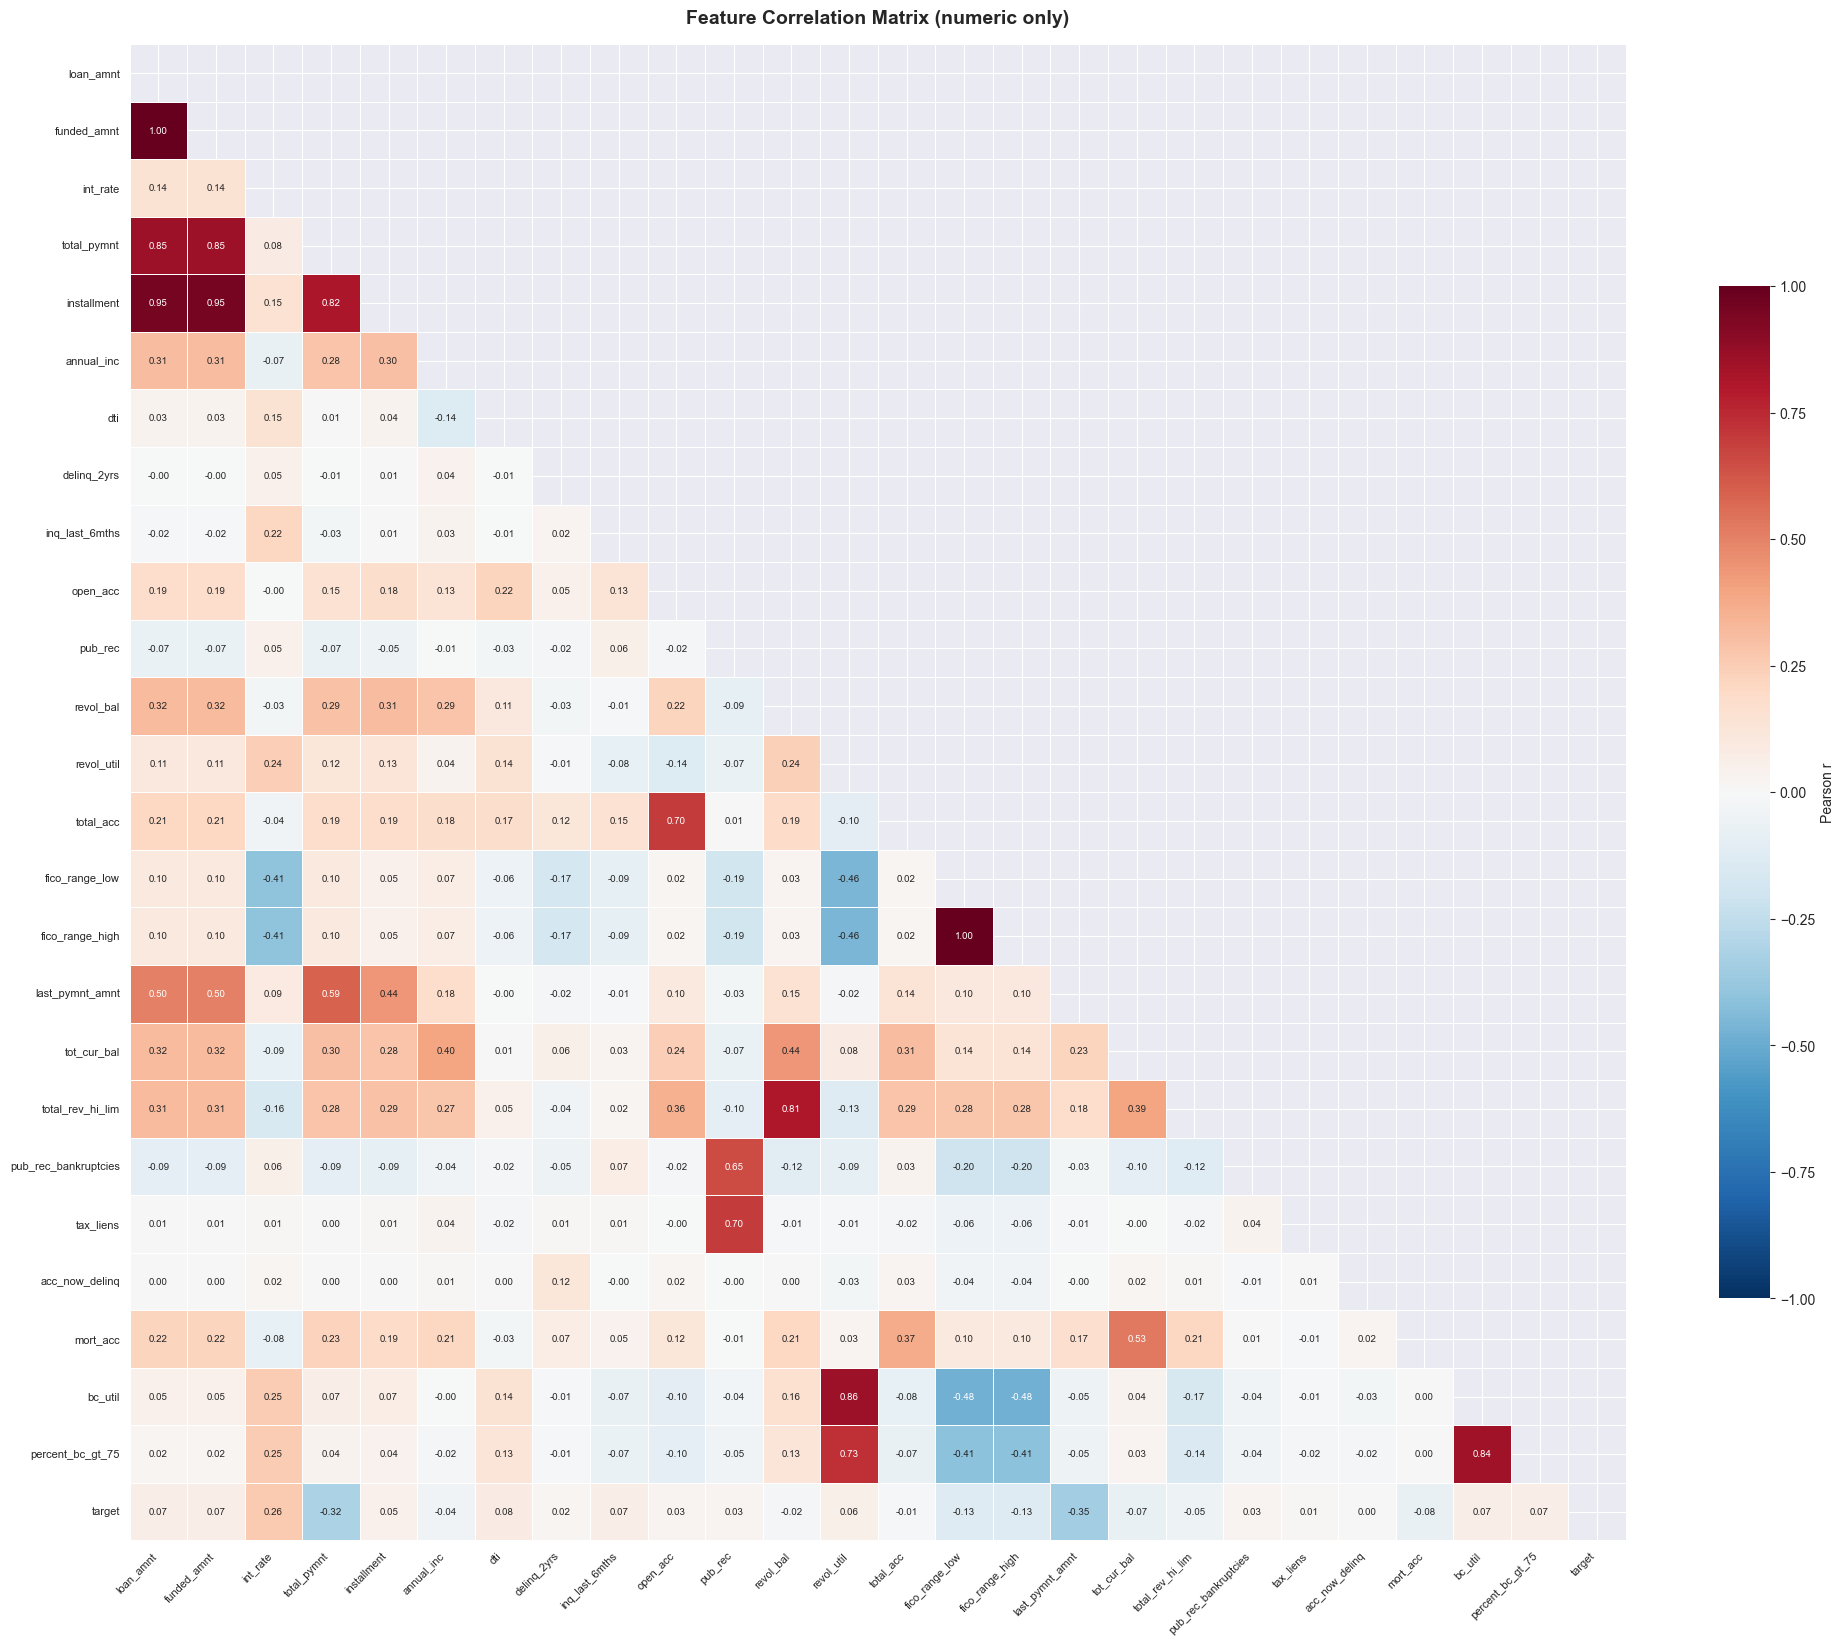


Top 10 most correlated pairs:
     feature_1        feature_2  correlation
fico_range_low  fico_range_high     1.000000
     loan_amnt      funded_amnt     0.999562
   funded_amnt      installment     0.954053
     loan_amnt      installment     0.953401
    revol_util          bc_util     0.855022
   funded_amnt      total_pymnt     0.854591
     loan_amnt      total_pymnt     0.854348
       bc_util percent_bc_gt_75     0.844702
   total_pymnt      installment     0.815842
     revol_bal total_rev_hi_lim     0.810244


In [232]:
# Feature correlation
feat_corr(df, FEATURES)

In [233]:
(
    df
    .null_count()
    .transpose(include_header=True, header_name="column")
    .rename({"column_0": "null_count"})
    .filter(pl.col("null_count") > 0)
    .sort("null_count", descending=True)
)

column,null_count
str,u32
"""emp_length""",78511
"""tot_cur_bal""",67527
"""total_rev_hi_lim""",67527
"""bc_util""",61912
"""percent_bc_gt_75""",61555
"""mort_acc""",47281
"""revol_util""",857
"""pub_rec_bankruptcies""",697
"""dti""",374


### Final features + derived

In [234]:
accepted_df["total_pymnt"].null_count()

0

In [235]:
FEATURES_FINAL = [
    # Loan info
    'loan_amnt', 'term', 'int_rate', "total_pymnt",
    'grade', 'sub_grade', 'purpose',
    # Borrower financials
    'annual_inc', 'dti', 'delinq_2yrs', 'inq_last_6mths',
    'open_acc', 'total_acc', 'pub_rec', 'revol_bal', 'revol_util',
    # Employment
    'emp_length', 'home_ownership',
    # Credit history
    'earliest_cr_line', 'fico_range_low',
    'last_pymnt_amnt', 'tot_cur_bal',
    # Risk
    'verification_status', 'pub_rec_bankruptcies', 'tax_liens',
    'acc_now_delinq', 'mort_acc', 'bc_util', 'percent_bc_gt_75',
    # Target
    'issue_d', 'target'
]

In [236]:
clean_df = accepted_df.select(FEATURES_FINAL)

# Merge rare home_ownership
clean_df = clean_df.with_columns(
    pl.col('home_ownership').replace({'NONE': 'OTHER', 'ANY': 'OTHER'})
)

# extract integer in sub_grade
clean_df = clean_df.with_columns(
    pl.col("sub_grade").str.extract(r'(\d+)').cast(pl.Int8)
  )
# emp_length → integer
clean_df = clean_df.with_columns(
    pl.col('emp_length')
    .str.replace('10\\+ years', '10 years')
    .str.replace('< 1 year', '0 years')
    .str.extract(r'(\d+)')
    .cast(pl.Int8)
    .alias('emp_length')
)

# Fill missing values

# Fill missing values
clean_df = clean_df.with_columns(
    [
        pl.col("emp_length").fill_null(
            pl.col("emp_length").median()
        ),
        pl.col("percent_bc_gt_75").fill_null(
            pl.col("percent_bc_gt_75").mean()
        ),
        pl.col("mort_acc").fill_null(
            pl.col("mort_acc").median()
        ),
        pl.col("dti").fill_null(
            pl.col("dti").mean()
        ),
        pl.col("bc_util").fill_null(
            pl.col("bc_util").mean()
        ),
        pl.col("pub_rec_bankruptcies").fill_null(0),
        pl.col("inq_last_6mths").fill_null(0),
    ]
)

# Derived features
clean_df = clean_df.with_columns([
    # Loan-to-Income Ratio
    (pl.col("loan_amnt") / (pl.col("annual_inc") + 1))
        .alias("loan_to_income"),

    # Active Accounts Ratio
    (pl.col("open_acc") / (pl.col("total_acc") + 1))
        .alias("active_accounts_ratio"),

    # Inquiries per Account
    (pl.col("inq_last_6mths") / (pl.col("total_acc") + 1))
        .alias("inquiries_per_account"),

    # Payment-to-Loan Ratio
    (pl.col("total_pymnt") / (pl.col("loan_amnt") + 1))
        .alias("payment_to_loan"),
        
    # Revolving debt relative to income
    (pl.col("revol_bal") / (pl.col("annual_inc") + 1))
        .alias("revolbal_to_income")
])

In [237]:
print(f"Data shape: {clean_df.shape}")     
print(f"Number of null columns: {clean_df.null_count()}")

Data shape: (1345310, 36)
Number of null columns: shape: (1, 36)
┌───────────┬──────┬──────────┬────────────┬───┬────────────┬────────────┬────────────┬────────────┐
│ loan_amnt ┆ term ┆ int_rate ┆ total_pymn ┆ … ┆ active_acc ┆ inquiries_ ┆ payment_to ┆ revolbal_t │
│ ---       ┆ ---  ┆ ---      ┆ t          ┆   ┆ ounts_rati ┆ per_accoun ┆ _loan      ┆ o_income   │
│ u32       ┆ u32  ┆ u32      ┆ ---        ┆   ┆ o          ┆ t          ┆ ---        ┆ ---        │
│           ┆      ┆          ┆ u32        ┆   ┆ ---        ┆ ---        ┆ u32        ┆ u32        │
│           ┆      ┆          ┆            ┆   ┆ u32        ┆ u32        ┆            ┆            │
╞═══════════╪══════╪══════════╪════════════╪═══╪════════════╪════════════╪════════════╪════════════╡
│ 0         ┆ 0    ┆ 0        ┆ 0          ┆ … ┆ 0          ┆ 0          ┆ 0          ┆ 0          │
└───────────┴──────┴──────────┴────────────┴───┴────────────┴────────────┴────────────┴────────────┘


In [238]:
null_summary = (
    clean_df
    .null_count()
    .transpose(
        include_header=True,
        header_name="column",
        column_names=["null_count"]
    )
    .filter(pl.col("null_count") > 0)
)

print(null_summary)

shape: (3, 2)
┌─────────────┬────────────┐
│ column      ┆ null_count │
│ ---         ┆ ---        │
│ str         ┆ u32        │
╞═════════════╪════════════╡
│ revol_util  ┆ 857        │
│ tot_cur_bal ┆ 67527      │
│ tax_liens   ┆ 39         │
└─────────────┴────────────┘


## Save cleaned file

In [239]:
clean_df.write_parquet("./processed_data/processed_accepted_df.parquet")